# Lab 2 - Phần 2.1: Cây quyết định (Decision Tree) & Rừng cây (Random Forest)
**Nội dung:** bài mẫu (Credit Card Default) + Bài tập 1 (Titanic) + Bài tập 2 (Diabetes).

**Dữ liệu:** `UCI_Credit_Card.csv` (hoặc `data.csv`), `titanic` (`train.csv`), `diabetes.csv`

In [1]:
import sys; sys.path.append(".")
from utils import *
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_graphviz
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import roc_auc_score, roc_curve

## A. Bài làm mẫu - Dự đoán vỡ nợ thẻ tín dụng (Credit Card Default)

In [2]:
cc = load_table("UCI_Credit_Card.csv", "data.csv", "*credit*.csv", "*default*.csv")
cc = cc.rename(columns={"default.payment.next.month": "default payment next month", "PAY_0": "PAY_1"})
overview(cc, "Credit Card Default")
target_cc = guess_column(cc, ["default payment next month", "default"])

[Đọc dữ liệu] data\UCI_Credit_Card.csv
===== Credit Card Default =====
Kích thước: 30000 dòng x 25 cột
Số dòng trùng lặp: 0


,dtype,missing,missing_%,n_unique
ID,int64,0,0.0,30000
LIMIT_BAL,float64,0,0.0,81
SEX,int64,0,0.0,2
EDUCATION,int64,0,0.0,7
MARRIAGE,int64,0,0.0,4
AGE,int64,0,0.0,56
PAY_1,int64,0,0.0,11
PAY_2,int64,0,0.0,11
PAY_3,int64,0,0.0,11
PAY_4,int64,0,0.0,11


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_1,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000.0,2,2,1,24,2,2,-1,-1,...,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,2,2,2,26,-1,2,0,0,...,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,2,2,2,34,0,0,0,0,...,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,4,50000.0,2,2,1,37,0,0,0,0,...,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,5,50000.0,1,2,1,57,-1,0,-1,0,...,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0


In [3]:
# Loại các cột không dùng (theo lab) nếu có, chỉ giữ biến số
drop_cols = [c for c in ["ID", "SEX", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6", "EDUCATION_CAT", "graduate school",
                         "high school", "none", "others", "university"] if c in cc.columns]
features_cc = [c for c in cc.select_dtypes(include="number").columns if c not in drop_cols + [target_cc]]
print("Số đặc trưng:", len(features_cc), "->", features_cc)
print("Tỷ lệ vỡ nợ:", round(cc[target_cc].mean(), 4))

X_train, X_test, y_train, y_test = train_test_split(cc[features_cc].values, cc[target_cc].values,
                                                    test_size=0.2, random_state=24)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Số đặc trưng: 17 -> ['LIMIT_BAL', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_1', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6']
Tỷ lệ vỡ nợ: 0.2212
Train: (24000, 17) | Test: (6000, 17)


### A.1 Cây quyết định độ sâu 2

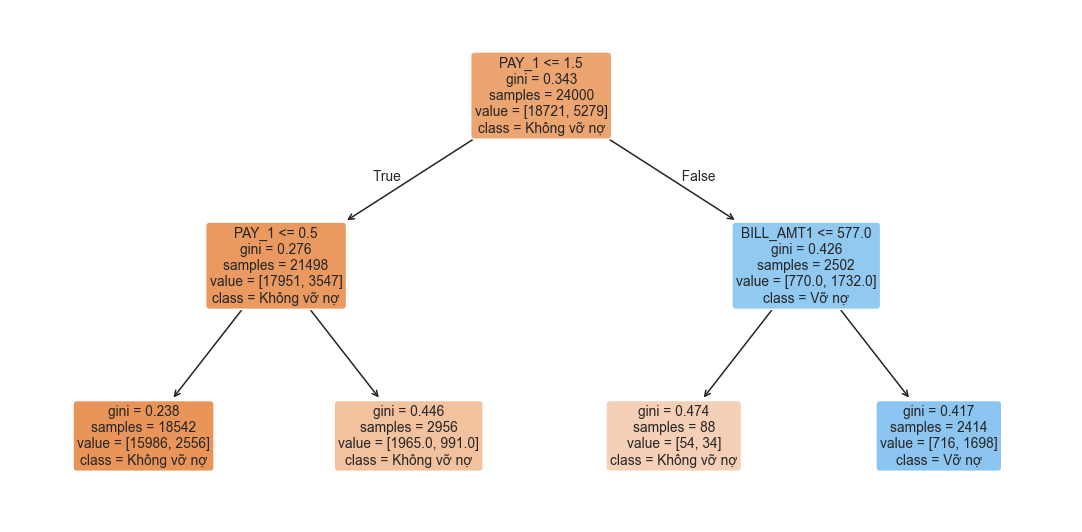

[Đã lưu] figures\s21_credit_tree_depth2.png
Bỏ qua graphviz: ExecutableNotFound


In [4]:
dt = DecisionTreeClassifier(max_depth=2, random_state=24).fit(X_train, y_train)
plt.figure(figsize=(10, 5))
plot_tree(dt, feature_names=features_cc, class_names=["Không vỡ nợ", "Vỡ nợ"], filled=True, rounded=True, fontsize=9)
save_fig("s21_credit_tree_depth2")

# (Tùy chọn) Xuất bằng graphviz nếu máy đã cài graphviz
try:
    import graphviz
    dot = export_graphviz(dt, out_file=None, filled=True, rounded=True, feature_names=features_cc,
                          class_names=["Không vỡ nợ", "Vỡ nợ"])
    graphviz.Source(dot).render(str(FIG_DIR / "s21_credit_tree_graphviz"), format="png", cleanup=True)
    print("Đã xuất graphviz")
except Exception as e:
    print("Bỏ qua graphviz:", type(e).__name__)

### A.2 Tìm `max_depth` tối ưu bằng GridSearchCV và chẩn đoán overfitting

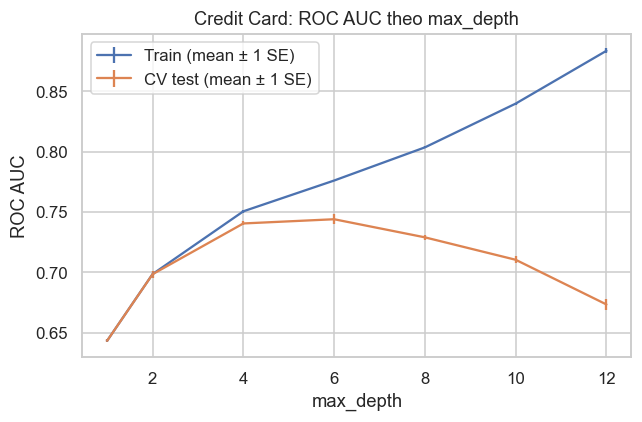

[Đã lưu] figures\s21_credit_depth_curve.png
Tốt nhất: {'max_depth': 6} | CV AUC = 0.7441


In [5]:
cv = 4
gs = GridSearchCV(DecisionTreeClassifier(random_state=24), {"max_depth": [1, 2, 4, 6, 8, 10, 12]},
                  scoring="roc_auc", cv=cv, refit=True, return_train_score=True)
gs.fit(X_train, y_train)
plot_cv_curve(pd.DataFrame(gs.cv_results_), "max_depth", "Credit Card: ROC AUC theo max_depth", "s21_credit_depth_curve", cv)
print("Tốt nhất:", gs.best_params_, "| CV AUC =", round(gs.best_score_, 4))

### A.3 Rừng cây: ảnh hưởng của số cây và độ sâu

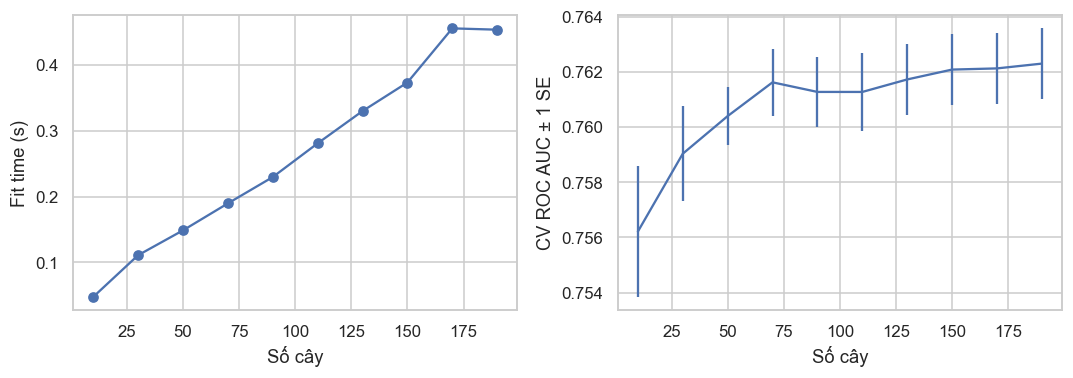

[Đã lưu] figures\s21_credit_rf_ntrees.png
n_estimators tốt nhất: {'n_estimators': 190}


In [6]:
rf = RandomForestClassifier(max_depth=3, random_state=24, n_jobs=-1)
gs_rf = GridSearchCV(rf, {"n_estimators": list(range(10, 210, 20))}, scoring="roc_auc", cv=cv, refit=True)
gs_rf.fit(X_train, y_train)
r = pd.DataFrame(gs_rf.cv_results_)
fig, axs = plt.subplots(1, 2, figsize=(10, 3.6))
axs[0].plot(r["param_n_estimators"].astype(float), r["mean_fit_time"], "-o"); axs[0].set_xlabel("Số cây"); axs[0].set_ylabel("Fit time (s)")
axs[1].errorbar(r["param_n_estimators"].astype(float), r["mean_test_score"], yerr=r["std_test_score"] / np.sqrt(cv))
axs[1].set_xlabel("Số cây"); axs[1].set_ylabel("CV ROC AUC ± 1 SE")
save_fig("s21_credit_rf_ntrees")
print("n_estimators tốt nhất:", gs_rf.best_params_)

Tốt nhất: {'max_depth': 9, 'max_features': 4} | CV AUC = 0.7749


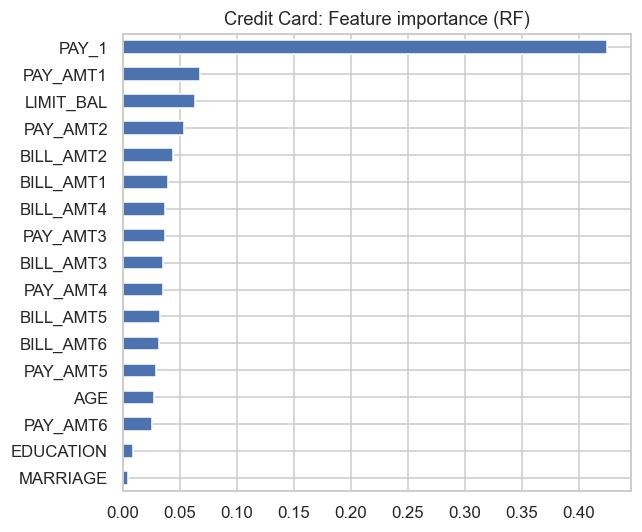

[Đã lưu] figures\s21_credit_feature_importance.png

===== Credit DT =====
              precision    recall  f1-score   support

       Không       0.83      0.96      0.89      4643
       Vỡ nợ       0.70      0.33      0.45      1357

    accuracy                           0.82      6000
   macro avg       0.76      0.65      0.67      6000
weighted avg       0.80      0.82      0.79      6000



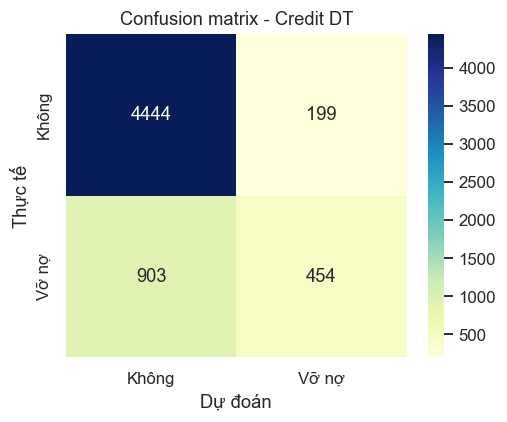

[Đã lưu] figures\cm_credit_dt.png

===== Credit RF =====
              precision    recall  f1-score   support

       Không       0.83      0.96      0.89      4643
       Vỡ nợ       0.72      0.32      0.44      1357

    accuracy                           0.82      6000
   macro avg       0.77      0.64      0.67      6000
weighted avg       0.80      0.82      0.79      6000



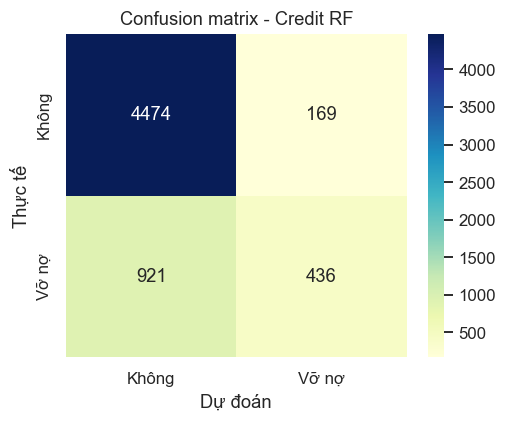

[Đã lưu] figures\cm_credit_rf.png


,accuracy,precision,recall,f1,roc_auc
model,,,,,
Credit DT,0.8163,0.6953,0.3346,0.4517,0.7500
Credit RF,0.8183,0.7207,0.3213,0.4444,0.7832


In [7]:
gs_rf2 = GridSearchCV(RandomForestClassifier(n_estimators=100, random_state=24, n_jobs=-1),
                      {"max_depth": [3, 6, 9, 12], "max_features": [4, 8, 12]},
                      scoring="roc_auc", cv=cv, refit=True)
gs_rf2.fit(X_train, y_train)
print("Tốt nhất:", gs_rf2.best_params_, "| CV AUC =", round(gs_rf2.best_score_, 4))
best_rf = gs_rf2.best_estimator_

# Feature importance
imp = pd.Series(best_rf.feature_importances_, index=features_cc).sort_values()
plt.figure(figsize=(6, 5)); imp.plot.barh(); plt.title("Credit Card: Feature importance (RF)")
save_fig("s21_credit_feature_importance")

# Đánh giá trên tập test
res_cc = [evaluate_model(gs.best_estimator_, X_test, y_test, "Credit DT", ["Không", "Vỡ nợ"]),
          evaluate_model(best_rf, X_test, y_test, "Credit RF", ["Không", "Vỡ nợ"])]
display(results_table(res_cc))

## B. Bài tập 1 - Titanic (dự đoán sống sót)

In [8]:
ti = load_table("titanic.csv", "train.csv", "Titanic-Dataset.csv", "*titanic*.csv")
overview(ti, "Titanic")

[Đọc dữ liệu] data\train.csv
===== Titanic =====
Kích thước: 891 dòng x 12 cột
Số dòng trùng lặp: 0


,dtype,missing,missing_%,n_unique
PassengerId,int64,0,0.00,891
Survived,int64,0,0.00,2
Pclass,int64,0,0.00,3
Name,object,0,0.00,891
Sex,object,0,0.00,2
Age,float64,177,19.87,88
SibSp,int64,0,0.00,7
Parch,int64,0,0.00,7
Ticket,object,0,0.00,681
Fare,float64,0,0.00,248


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


**Tiền xử lý & tạo đặc trưng:** Title từ Name, FamilySize, IsAlone, điền thiếu Age/Embarked/Fare, mã hóa Sex/Embarked

In [9]:
df = ti.copy()
df["Title"] = df["Name"].str.extract(r",\s*([^\.]+)\.", expand=False).str.strip()
df["Title"] = df["Title"].replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})
rare = df["Title"].value_counts()[lambda s: s < 10].index
df["Title"] = df["Title"].replace(list(rare), "Rare")
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
df["IsAlone"] = (df["FamilySize"] == 1).astype(int)
df["HasCabin"] = df["Cabin"].notna().astype(int)

df["Age"] = df["Age"].fillna(df.groupby(["Title", "Pclass"])["Age"].transform("median"))
df["Age"] = df["Age"].fillna(df["Age"].median())
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])
df["Fare"] = df["Fare"].fillna(df["Fare"].median())
df["Sex"] = df["Sex"].map({"male": 0, "female": 1})

df = pd.get_dummies(df, columns=["Embarked", "Title"], drop_first=False, dtype=int)
df = df.drop(columns=["PassengerId", "Name", "Ticket", "Cabin"], errors="ignore")
print("Còn thiếu:", df.isna().sum().sum(), "| Kích thước:", df.shape)
display(df.head())

Còn thiếu: 0 | Kích thước: (891, 18)


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,FamilySize,IsAlone,HasCabin,Embarked_C,Embarked_Q,Embarked_S,Title_Master,Title_Miss,Title_Mr,Title_Mrs,Title_Rare
0,0,3,0,22.0,1,0,7.2500,2,0,0,0,0,1,0,0,1,0,0
1,1,1,1,38.0,1,0,71.2833,2,0,1,1,0,0,0,0,0,1,0
2,1,3,1,26.0,0,0,7.9250,1,1,0,0,0,1,0,1,0,0,0
3,1,1,1,35.0,1,0,53.1000,2,0,1,0,0,1,0,0,0,1,0
4,0,3,0,35.0,0,0,8.0500,1,1,0,0,0,1,0,0,1,0,0


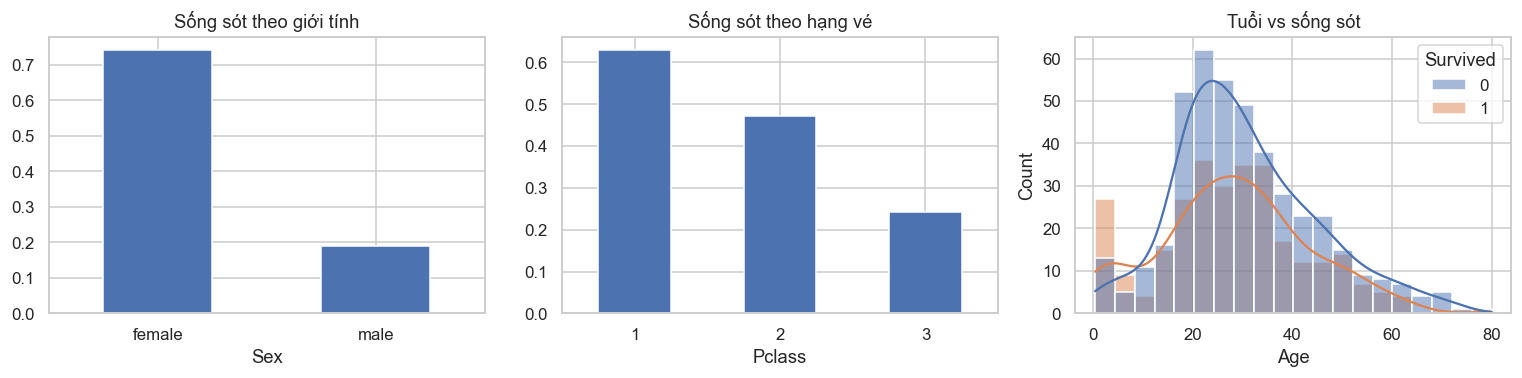

[Đã lưu] figures\s21_titanic_eda.png


In [10]:
# EDA nhanh: tỷ lệ sống sót theo giới tính, hạng vé
fig, axs = plt.subplots(1, 3, figsize=(14, 3.6))
ti.groupby("Sex")["Survived"].mean().plot.bar(ax=axs[0], rot=0, title="Sống sót theo giới tính")
ti.groupby("Pclass")["Survived"].mean().plot.bar(ax=axs[1], rot=0, title="Sống sót theo hạng vé")
sns.histplot(data=ti, x="Age", hue="Survived", kde=True, ax=axs[2]); axs[2].set_title("Tuổi vs sống sót")
save_fig("s21_titanic_eda")

[DT không giới hạn] depth=17 | acc train=0.987 | acc test=0.782  -> chênh lệch lớn = overfitting

===== Titanic DT (không giới hạn) =====
              precision    recall  f1-score   support

        Chết       0.83      0.81      0.82       110
        Sống       0.71      0.74      0.72        69

    accuracy                           0.78       179
   macro avg       0.77      0.77      0.77       179
weighted avg       0.78      0.78      0.78       179



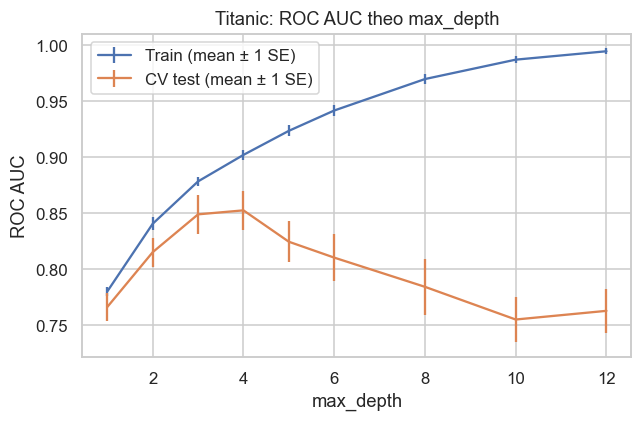

[Đã lưu] figures\titanic_dt_depth_curve.png
max_depth tốt nhất: {'max_depth': 4} | CV AUC = 0.8526
DT tốt nhất: {'criterion': 'gini', 'max_depth': 4, 'min_samples_leaf': 1} | CV AUC = 0.8526

===== Titanic DT (tối ưu) =====
              precision    recall  f1-score   support

        Chết       0.79      0.91      0.85       110
        Sống       0.81      0.62      0.70        69

    accuracy                           0.80       179
   macro avg       0.80      0.77      0.78       179
weighted avg       0.80      0.80      0.79       179



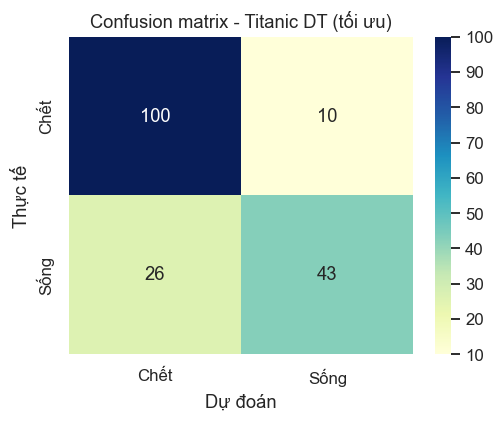

[Đã lưu] figures\cm_titanic_dt_toi_uu.png


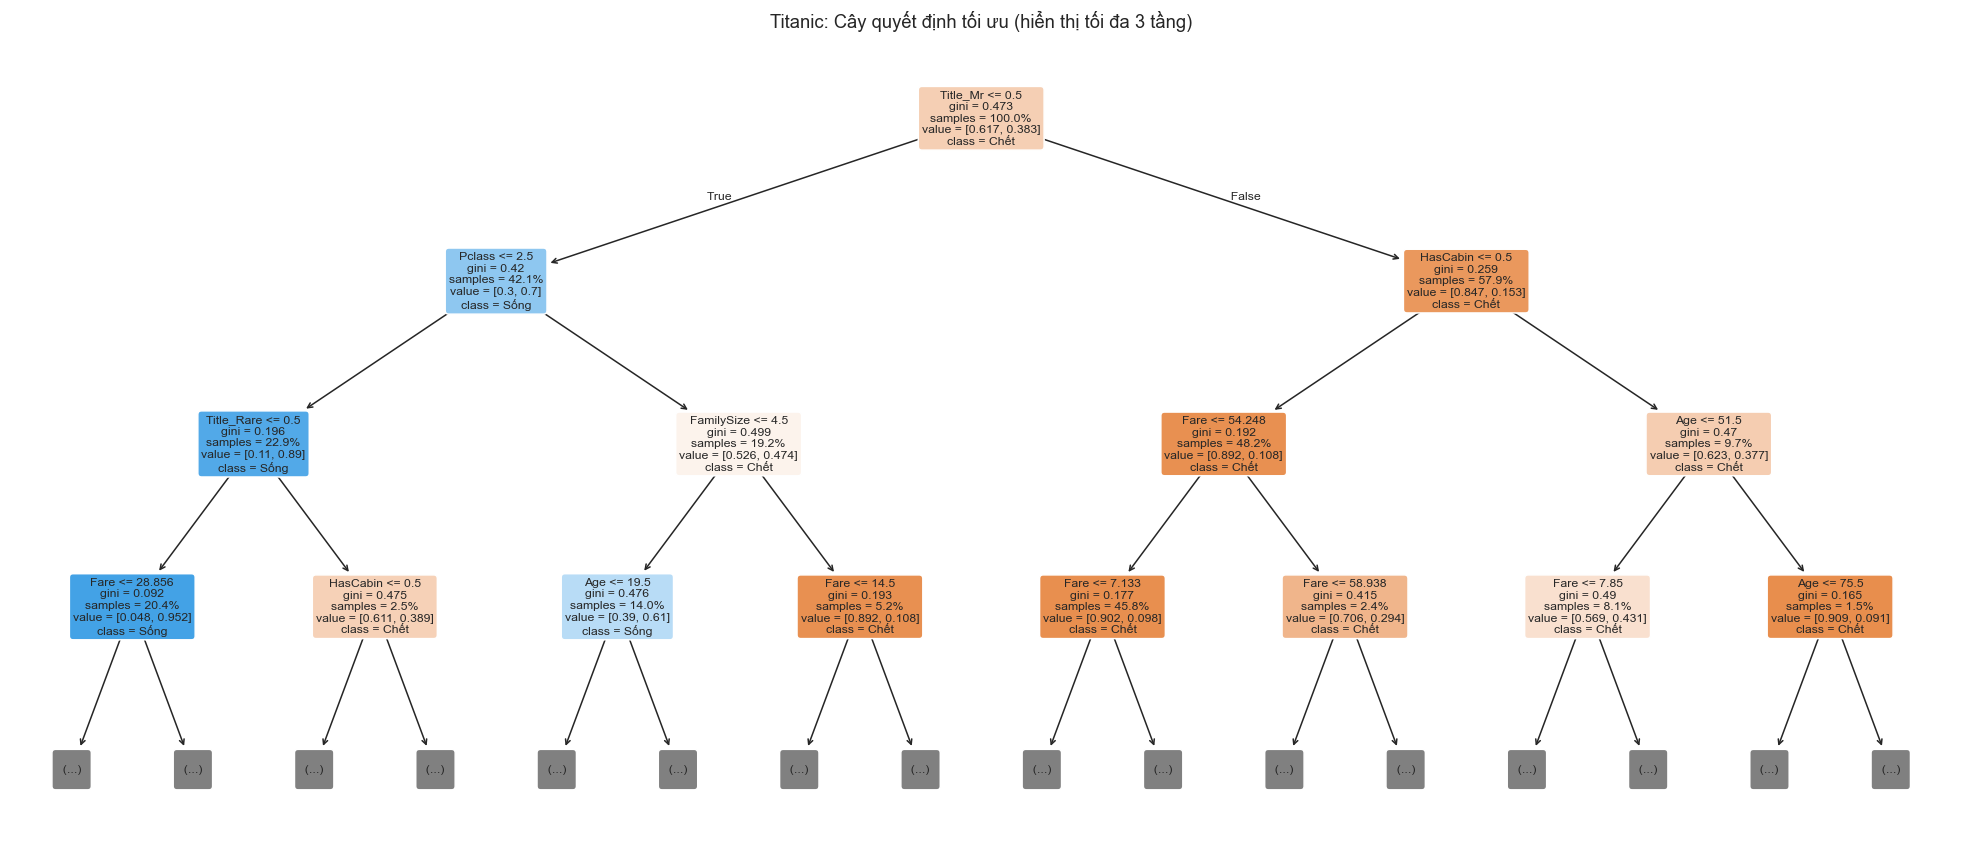

[Đã lưu] figures\titanic_decision_tree.png


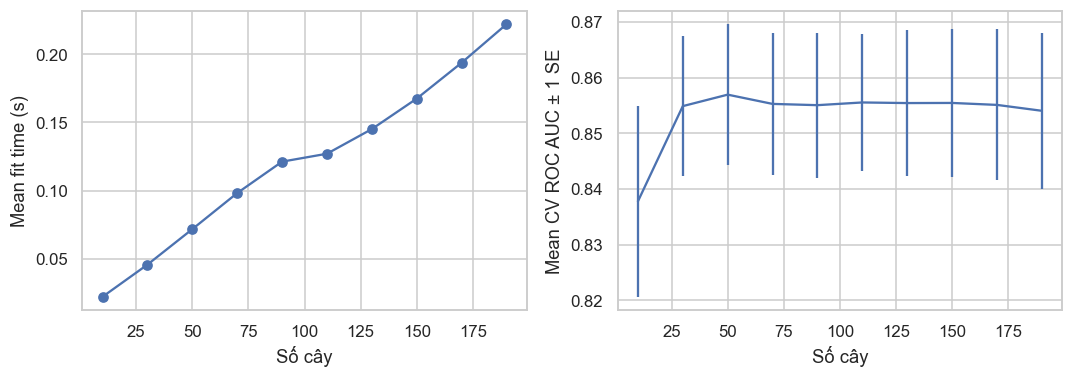

[Đã lưu] figures\titanic_rf_ntrees.png
RF tốt nhất: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 3, 'n_estimators': 100} | CV AUC = 0.8784
[RF tối ưu] acc train=0.903 | acc test=0.804

===== Titanic RF (tối ưu) =====
              precision    recall  f1-score   support

        Chết       0.82      0.88      0.85       110
        Sống       0.78      0.68      0.73        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179



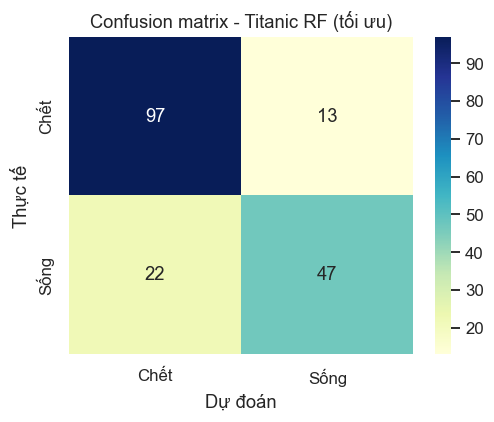

[Đã lưu] figures\cm_titanic_rf_toi_uu.png


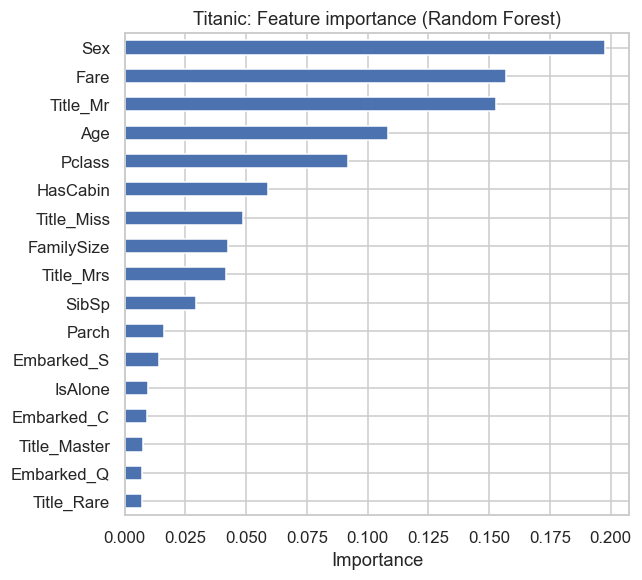

[Đã lưu] figures\titanic_feature_importance.png


,importance
Sex,0.1977
Fare,0.1569
Title_Mr,0.1529
Age,0.1082
Pclass,0.0919
HasCabin,0.0589
Title_Miss,0.0486
FamilySize,0.0427
Title_Mrs,0.0418
SibSp,0.0293


,accuracy,precision,recall,f1,roc_auc
model,,,,,
Titanic RF (tối ưu),0.8045,0.7833,0.6812,0.7287,0.8489
Titanic DT (không giới hạn),0.7821,0.7083,0.7391,0.7234,0.7638
Titanic DT (tối ưu),0.7989,0.8113,0.6232,0.7049,0.8323


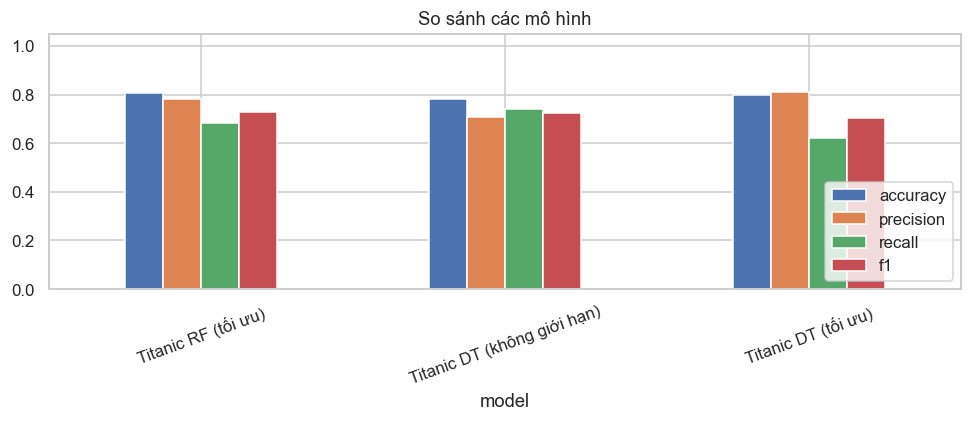

[Đã lưu] figures\titanic_compare.png


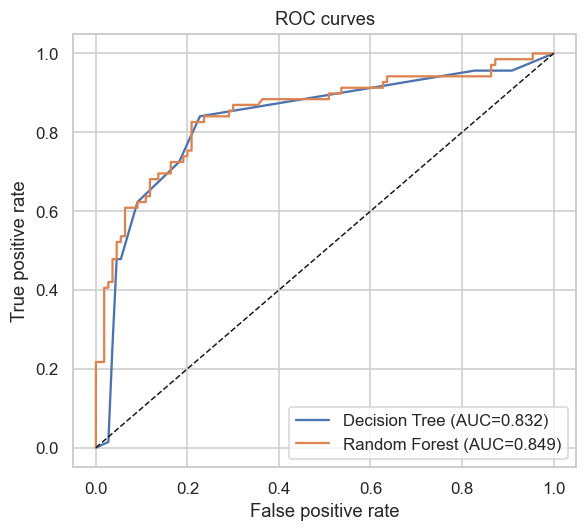

[Đã lưu] figures\titanic_roc.png


In [11]:
y = df["Survived"]; X = df.drop(columns="Survived")
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
tab_ti, models_ti = tree_forest_experiment(X_tr, X_te, y_tr, y_te, X.columns, ["Chết", "Sống"], "Titanic")

## C. Bài tập 2 - Diabetes

In [12]:
db, target = load_diabetes(clean_zeros=True)
y = db[target]; X = db.drop(columns=target)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

# Điền thiếu bằng median của tập train (tránh rò rỉ dữ liệu)
imp = SimpleImputer(strategy="median").fit(X_tr)
X_tr = pd.DataFrame(imp.transform(X_tr), columns=X.columns)
X_te = pd.DataFrame(imp.transform(X_te), columns=X.columns)
y_tr = y_tr.reset_index(drop=True); y_te = y_te.reset_index(drop=True)
print(f"Train {X_tr.shape} | Test {X_te.shape} | Tỷ lệ bệnh train/test: {y_tr.mean():.3f}/{y_te.mean():.3f}")

[Đọc dữ liệu] data\diabetes.csv
Train (614, 8) | Test (154, 8) | Tỷ lệ bệnh train/test: 0.349/0.351


[DT không giới hạn] depth=14 | acc train=1.000 | acc test=0.682  -> chênh lệch lớn = overfitting

===== Diabetes DT (không giới hạn) =====
              precision    recall  f1-score   support

  Không bệnh       0.74      0.79      0.76       100
     Có bệnh       0.55      0.48      0.51        54

    accuracy                           0.68       154
   macro avg       0.65      0.64      0.64       154
weighted avg       0.67      0.68      0.68       154



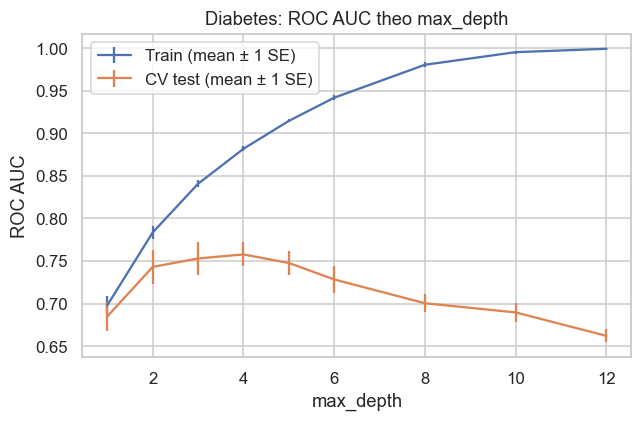

[Đã lưu] figures\diabetes_dt_depth_curve.png
max_depth tốt nhất: {'max_depth': 4} | CV AUC = 0.7577
DT tốt nhất: {'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 20} | CV AUC = 0.8035

===== Diabetes DT (tối ưu) =====
              precision    recall  f1-score   support

  Không bệnh       0.86      0.83      0.85       100
     Có bệnh       0.71      0.76      0.73        54

    accuracy                           0.81       154
   macro avg       0.79      0.79      0.79       154
weighted avg       0.81      0.81      0.81       154



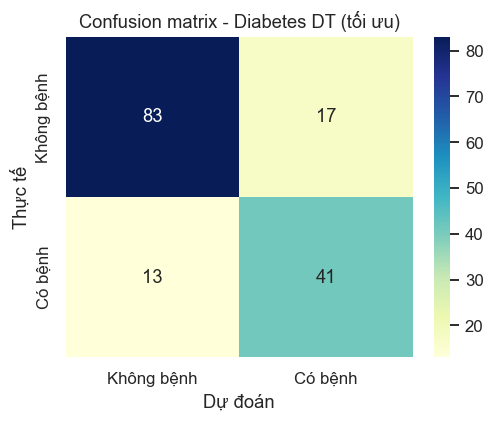

[Đã lưu] figures\cm_diabetes_dt_toi_uu.png


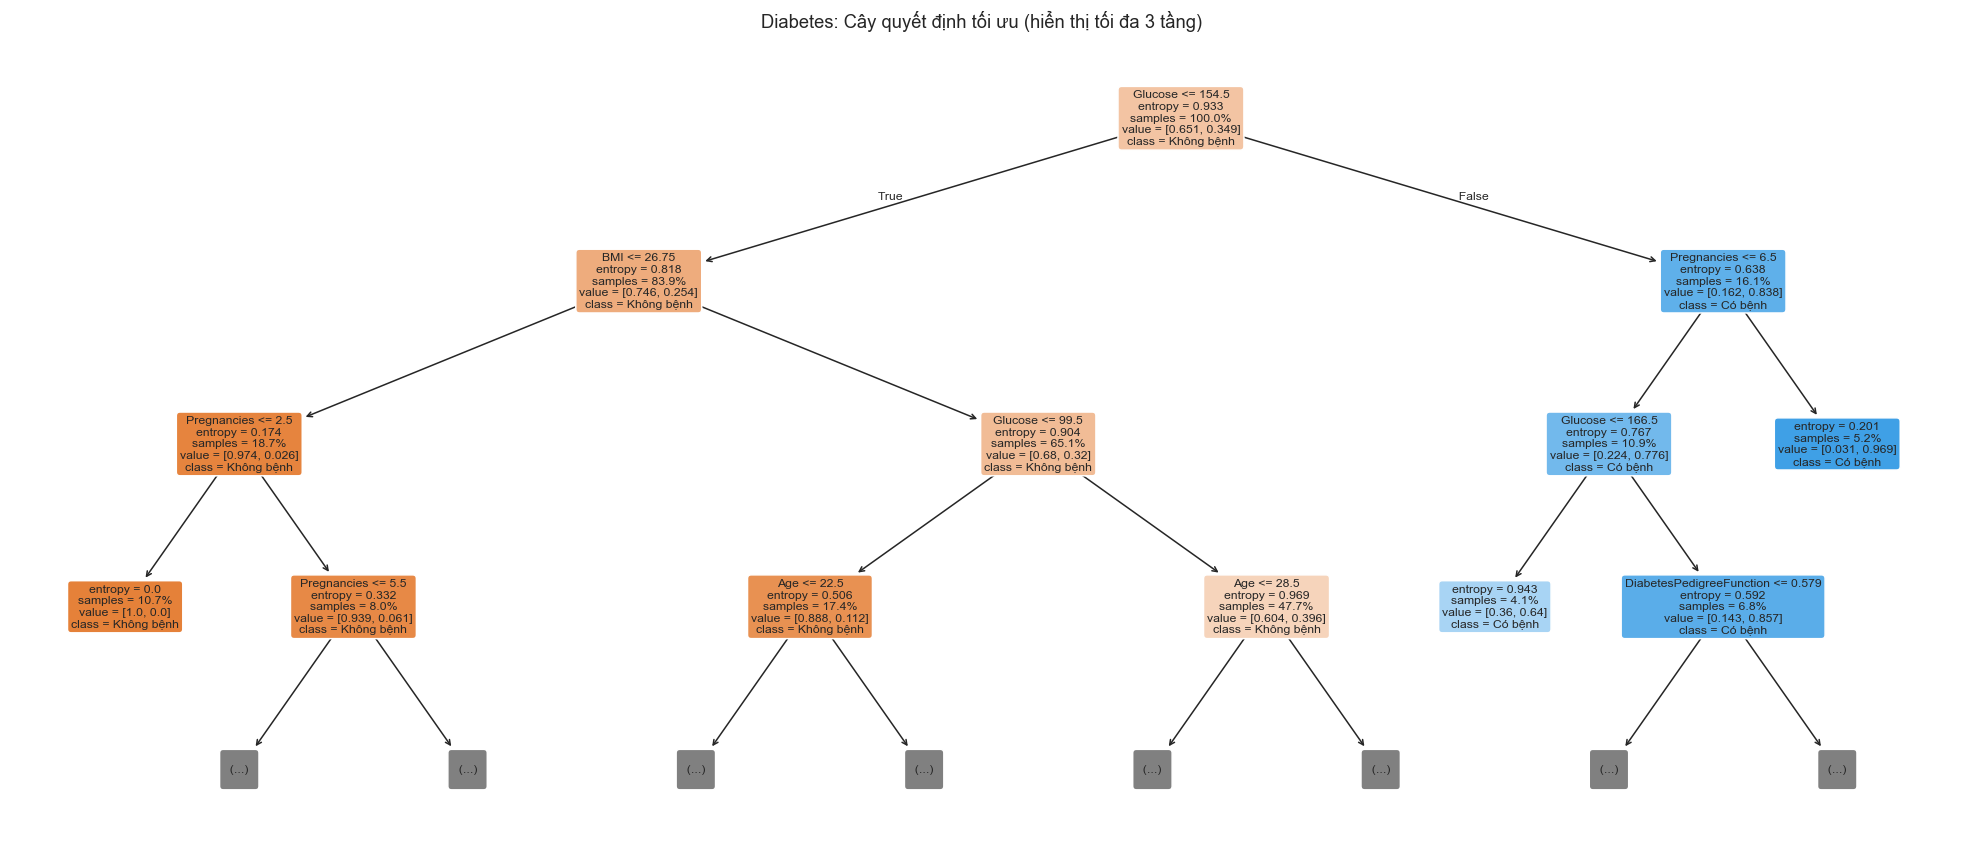

[Đã lưu] figures\diabetes_decision_tree.png


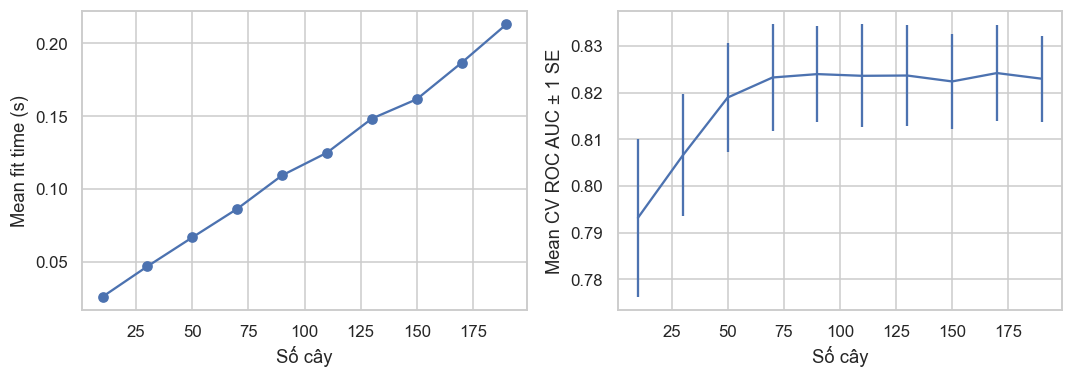

[Đã lưu] figures\diabetes_rf_ntrees.png
RF tốt nhất: {'max_depth': 5, 'max_features': 'log2', 'min_samples_leaf': 3, 'n_estimators': 200} | CV AUC = 0.8412
[RF tối ưu] acc train=0.842 | acc test=0.721

===== Diabetes RF (tối ưu) =====
              precision    recall  f1-score   support

  Không bệnh       0.75      0.85      0.80       100
     Có bệnh       0.63      0.48      0.55        54

    accuracy                           0.72       154
   macro avg       0.69      0.67      0.67       154
weighted avg       0.71      0.72      0.71       154



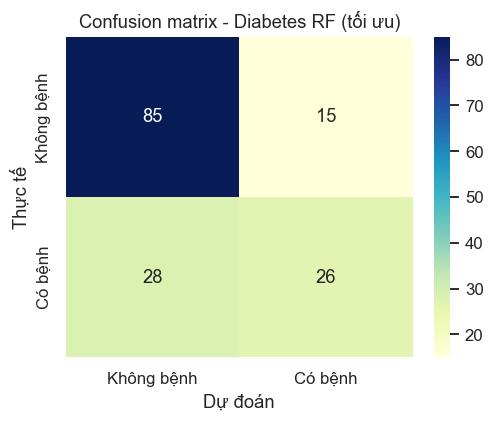

[Đã lưu] figures\cm_diabetes_rf_toi_uu.png


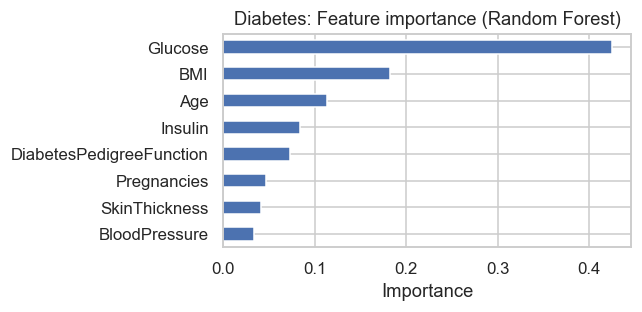

[Đã lưu] figures\diabetes_feature_importance.png


,importance
Glucose,0.4250
BMI,0.1825
Age,0.1134
Insulin,0.0840
DiabetesPedigreeFunction,0.0734
Pregnancies,0.0465
SkinThickness,0.0413
BloodPressure,0.0339


,accuracy,precision,recall,f1,roc_auc
model,,,,,
Diabetes DT (tối ưu),0.8052,0.7069,0.7593,0.7321,0.8313
Diabetes RF (tối ưu),0.7208,0.6341,0.4815,0.5474,0.8096
Diabetes DT (không giới hạn),0.6818,0.5532,0.4815,0.5149,0.6357


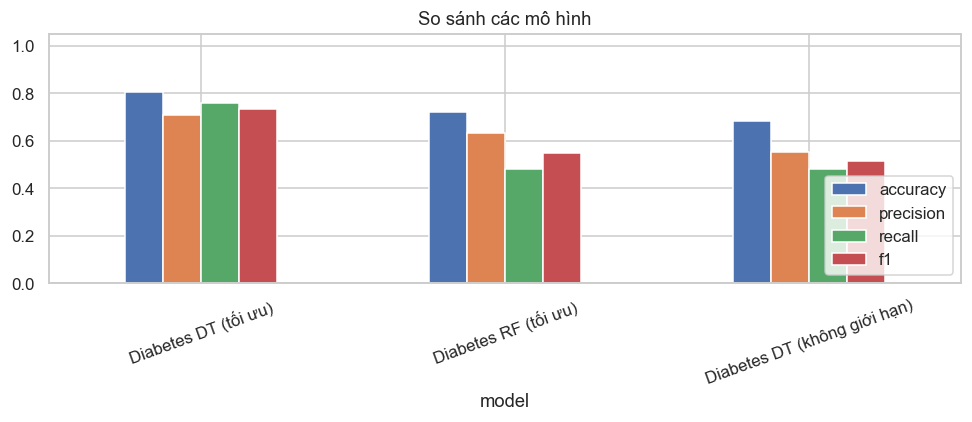

[Đã lưu] figures\diabetes_compare.png


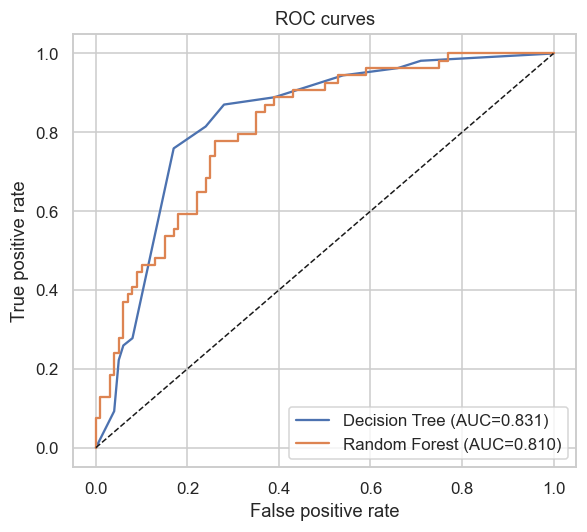

[Đã lưu] figures\diabetes_roc.png


In [13]:
tab_db, models_db = tree_forest_experiment(X_tr, X_te, y_tr, y_te, X.columns, ["Không bệnh", "Có bệnh"], "Diabetes")

## D. Tổng hợp kết quả

In [14]:
summary = pd.concat({"Titanic": tab_ti, "Diabetes": tab_db}, names=["dataset"])
display(summary)
summary.to_csv(OUT_DIR / "s21_summary.csv")

accuracy  precision  recall      f1  \
dataset  model                                                               
Titanic  Titanic RF (tối ưu)             0.8045     0.7833  0.6812  0.7287   
         Titanic DT (không giới hạn)     0.7821     0.7083  0.7391  0.7234   
         Titanic DT (tối ưu)             0.7989     0.8113  0.6232  0.7049   
Diabetes Diabetes DT (tối ưu)            0.8052     0.7069  0.7593  0.7321   
         Diabetes RF (tối ưu)            0.7208     0.6341  0.4815  0.5474   
         Diabetes DT (không giới hạn)    0.6818     0.5532  0.4815  0.5149   

                                       roc_auc  
dataset  model                                  
Titanic  Titanic RF (tối ưu)            0.8489  
         Titanic DT (không giới hạn)    0.7638  
         Titanic DT (tối ưu)            0.8323  
Diabetes Diabetes DT (tối ưu)           0.8313  
         Diabetes RF (tối ưu)           0.8096  
         Diabetes DT (không giới hạn)   0.6357